In [1]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#in this code let's use train an AI to play a game of battleship
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

In [2]:
#@@@@@@@@@@@@@@@@@@@@@@@
#import useful libraries
#@@@@@@@@@@@@@@@@@@@@@@@
import numpy as np
import copy
import seaborn as sb

from tqdm import tqdm
from IPython.display import clear_output
import time
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import pickle


In [3]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#two classes for these two environments
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class Battleship:
    '''A class to manage the board'''
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.hit_streak = 0
        self.last_hit_coordinate = None    #(row, col) of the latest hit on a ship not yet sunk
        self.true_state = np.zeros([config['n'],config['n']],dtype = int)
        self.ship_cells = []    #list of (rows, cols) index arrays, one per ship
        self.state = np.zeros([config['n'],config['n']],dtype = int)    #TODO -- consider how to change this
        self.old_state = copy.deepcopy(self.state)

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def position_maker(self,ship):
        '''A function to choose a position for a ship
            Takes:
                self -- class instance info above
                ship -- int, the index in the list of ship lengths
            Returns:
                an int, int pair, the coordinates of the first cell the ship occupies
        '''
        coord_1 = np.random.choice(list(range(self.config['n'] - self.config['ships'][ship] + 1)))    #choose first coordinate, guaranteed to have ship on board
        coord_2 = np.random.choice(list(range(self.config['n'])))    #choose second coordinate
        return coord_1,coord_2

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def check_empty(self,coord_1,coord_2,vert,ship):
        '''A function to make sure the proposed location is currently empty
            Takes:
                self -- class instance info above
                coord_1 -- int, the first coordinate, constrained to ensure the ship lies on the board
                coord_2 -- int, the second coordinate
                vert -- boolean, whether to orient the ship vertically or horizontally
                ship -- int, the index in the list of ship lengths
            Returns:
                a boolean, indicating if the placement is legal
        '''
        if vert:    #if the ship is oriented vertically...
            if sum(self.true_state[coord_1 + list(range(self.config['ships'][ship])),coord_2]) > 0:    #and if there is another ship lying across its path...
                empty = False    #set the empty indicator to false
            else:    #otherwise if the proposed location is empty...
                empty = True    #set the empty indicator to true
        else:    #if the ship is oriented horizontally...
            if sum(self.true_state[coord_2,coord_1 + list(range(self.config['ships'][ship]))]) > 0:    #and if there is anther ship lying across its path...
                empty = False    #set the empty indicator to false
            else:    #otherwise if the proposed location is empty...
                empty = True    #set the empty indicator to true
        return empty

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def place_ship(self,ship):
        '''A function to put a single ship on the board
            Takes:
                self -- class instance info above
                ship -- int, the index in the list of ship lengths
        '''
        empty = False    #init the stopping criterion
        while not empty:    #while we should keep going...
            coord_1,coord_2 = self.position_maker(ship)    #sample a position for the ship
            vert = np.random.uniform() < 0.5    #choose whether ship is horizontal or vertical
            empty = self.check_empty(coord_1,coord_2,vert,ship)    #check if legal
        span = coord_1 + np.arange(self.config['ships'][ship])    #cells along the ship's length
        if vert:    #if the ship is vertical...
            cells = (span, np.full(len(span), coord_2))
        else:    #if the ship is horizontal...
            cells = (np.full(len(span), coord_2), span)
        self.true_state[cells] = 1    #place on board
        self.ship_cells.append(cells)    #remember where this ship is
        vert = np.random.uniform() < 0.5    #choose whether ship is horizontal or vertical

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_board(self):
        '''A function to put all ships on the board
            Takes:
                self -- class instance info above
        '''
        self.true_state = np.zeros([self.config['n'],self.config['n']],dtype = int)
        self.ship_cells = []    #clear old ship locations
        for j in range(len(self.config['ships'])):    #loop over ship lengths
            self.place_ship(j)    #put on board'

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reset(self):
        '''A function to reset the board
            Takes:
                self -- class instance info above
        '''
        self.hit_streak = 0
        self.last_hit_coordinate = None    #no hit yet this game
        self.true_state = np.zeros([self.config['n'],self.config['n']],dtype = int)    #reset the hidden state
        self.make_board()    #place ships again
        self.state = np.zeros([self.config['n'],self.config['n']],dtype = int)    #reset the observed state
        self.old_state = copy.deepcopy(self.state)
        

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def check_win(self):
        '''A function to check whether the agent has won
            Takes:
                self -- class instance info above
            Returns:
                a boolean, indicating if the agent sank all the ships
        '''
        if np.sum(self.state>0) == sum(self.config['ships']):    #if the number of hits is equal to the total length of ships...
            return True    #return true -- the agent won!
        else:    #otherwise...
            return False    #return false -- the game is still going

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def ships_remaining(self):
        '''A function to find which ships have not been sunk yet
            Takes:
                self -- class instance info above
            Returns:
                a tuple of ints, the lengths of the ships still afloat
        '''
        return tuple(length for length, cells in zip(self.config['ships'], self.ship_cells)
                     if not np.all(self.state[cells] == 1))    #afloat if any cell is not yet hit

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def unsunk_hits(self):
        '''A function to find the hits on ships that have not been sunk yet'''
        return tuple(sorted((int(r), int(c)) for cells in self.ship_cells
                            if not np.all(self.state[cells] == 1)
                            for r, c in zip(*cells) if self.state[r, c] == 1))

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def get_state(self):
        board = tuple(map(tuple, self.state))    #hits and misses on the observed board
        return (board, self.ships_remaining(), self.unsunk_hits())

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reward(self,):

        # Reward the agent for trying to shoot adjacent spots
        adjacent_reward = 3
        # Reward the agent for hitting the ship
        hit_reward = 5
        # Give no reward if the agent miss
        miss_reward = 0
        
        a = self.last_action    #the action just taken, set in step
        r = 0
        # Reward shooting next to the last hit (up, down, left, right), even on a miss
        if self.last_hit_coordinate is not None:
            last_row, last_col = self.last_hit_coordinate
            if abs(a['row'] - last_row) + abs(a['col'] - last_col) == 1:    #exactly 1 tile away, no diagonals
                r += adjacent_reward
        # Reward for hitting
        if self.state[a['row'],a['col']] == 1:
            r += hit_reward
            #remember the latest hit
            self.last_hit_coordinate = (a['row'], a['col'])    
            #find the ship that was hit...
            for cells in self.ship_cells:    
                if np.any((cells[0] == a['row']) & (cells[1] == a['col'])) and np.all(self.state[cells] == 1):   
                    self.last_hit_coordinate = None    #ship destroyed, nothing to follow up on
            return r
        return miss_reward
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def step(self,a):
        '''A function to update the state given the true enemy fleet locations'''
        if self.true_state[a['row'],a['col']] > 0:    #if there is a ship at the chosen location...
            self.state[a['row'],a['col']] = 1    #record a hit on the observed state as a 1
        else:    #if there is no ship
            self.state[a['row'],a['col']] = -1    #record a miss on the observed state as a -1
        done = self.check_win()    #check to see if the agent has won
        if done:
            r = 10#max(10*np.sum(self.state == 0),10)
        else:
            self.last_action = a    #let reward() see the action
            r = self.reward()    #WILL NOT WORK RIGHT NOW -- NEED TO SPECIFIY REWARD FUNCTION
        self.old_state = copy.deepcopy(self.state)
        return{'state':self.get_state(),'reward':r,'done':done}
        

In [4]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#A simple CNN architecture
class CNN(nn.Module):
    def __init__(self, in_channels=1):
        super(CNN, self).__init__()

        # Input: (batch_size, in_channels, 6, 6)
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding=1)  # -> (32, 6, 6)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # -> (64, 6, 6)
        self.conv3 = nn.Conv2d(64, 1, kernel_size=1)  # -> (1, 6, 6)

    def forward(self, x):
        x = F.relu(self.conv1(x))  # (batch_size, 32, 6, 6)
        x = F.relu(self.conv2(x))  # (batch_size, 64, 6, 6)
        q_map = self.conv3(x)      # (batch_size, 1, 6, 6)
        return q_map.squeeze(1)    # -> (batch_size, 6, 6)


In [41]:
# The following was generated with the aid of claude
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
from collections import deque

class Agent:
    '''A class to manage the chase'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config, state_idx=(0,)):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
                     state_idx, list of indices into Battleship.get_state's (board, ships_left)
                        that the agent uses as its state, e.g. [0] board only, [0, 1] full;
                        index 1 needs config['ships'], the list of ship lengths
        '''
        self.config = config    #save the config file
        self.A_s = self.config['A']    #save the action set
        self.state_idx = tuple(state_idx)    #save which parts of the state to use
        #init the deep learning model
        n_channels = sum({0: 1, 1: len(self.config['ships']), 2: 1}[i] for i in self.state_idx)
        self.Q = CNN(n_channels)    #Q(s,.|w)
        self.optimizer = optim.Adam(self.Q.parameters(), lr=self.config['alpha'])    #takes the gradient steps
        #copy the target approximator
        self.Q_target = copy.deepcopy(self.Q)    #w' = w
        #init the replay buffer
        self.replay_buffer = deque()    #holds (s, a, r, s', done) tuples
        self.n_updates = 0    #number of gradient steps taken, used to time target updates

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_state(self, s):
        '''A function to turn the environment's state into stacked n x n channels for the CNN
            Takes:
                s -- the state from Battleship.get_state, (board, ships_left, unsunk_hits)
            Returns:
                an array of shape (channels, n, n):
                    index 0 -- the board, one channel (1 = hit, -1 = miss, 0 = untried)
                    index 1 -- ships still afloat, one constant channel per ship (1 if afloat)
                    index 2 -- unsunk hits, one channel with a 1 on each hit of a ship not yet sunk
        '''
        n = self.config['n']
        channels = []
        for i in self.state_idx:
            if i == 0:
                channels.append(np.array(s[0], dtype=np.float32))
            elif i == 1:
                afloat = list(s[1])
                for length in self.config['ships']:
                    is_afloat = length in afloat
                    if is_afloat:
                        afloat.remove(length)    #handles ships of the same length
                    channels.append(np.full((n, n), float(is_afloat), dtype=np.float32))
            elif i == 2:
                hits = np.zeros((n, n), dtype=np.float32)
                for r, c in s[2]:
                    hits[r, c] = 1
                channels.append(hits)
        return np.stack(channels)

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_Q_target(self,):
        '''A function to update the target approximator
        '''
        #TODO
        self.Q_target.load_state_dict(self.Q.state_dict())    #w' <- w
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def purge_replay_buffer(self,):
        '''A function to keep the replay buffer within memory limits
        '''
        while len(self.replay_buffer) > self.config['M']:    #if |D| > M...
            self.replay_buffer.popleft()    #drop the oldest
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def forward_pass(self, s, model=None):
        '''A function to compute the forward pass
        '''
        if model is None:    #default to the main approximator
            model = self.Q
        x = torch.as_tensor(np.array(s), dtype=torch.float32)
        if x.dim() == 3:    #a single state...
            x = x.unsqueeze(0)    #...becomes a batch of one
        q_map = model(x)    #(B, channels, n, n) -> (B, n, n)
        return q_map.reshape(q_map.shape[0], -1)    #(B, n*n), index row*n + col matches A
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def valid_actions(self, env_s):
        board = np.array(env_s[0]).flatten()
        return board == 0

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self, s, valid):
        '''A function to choose actions using Q-values
        '''
        #TODO
        if np.random.uniform() < self.config['epsilon']:    #with probability epsilon...
            return int(np.random.choice(np.flatnonzero(valid)))
        with torch.no_grad():
            q = self.forward_pass(s)[0]
        q[~torch.as_tensor(valid)] = -np.inf
        return int(torch.argmax(q))    #exploit: argmax_a Q(s,a|w)
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_batch(self):
        '''A function to make a batch for updating Q
        '''
        #TODO
        idx = np.random.choice(len(self.replay_buffer), self.config['B'], replace=False)    #sample B tuples uniformly
        s, a, r, s_prime, done, valid_next = zip(*[self.replay_buffer[i] for i in idx])
        return (np.array(s),
                torch.as_tensor(a, dtype=torch.long),
                torch.as_tensor(r, dtype=torch.float32),
                np.array(s_prime),
                torch.as_tensor(done, dtype=torch.float32),
                torch.as_tensor(np.array(valid_next)))

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_Q_value(self,):
        '''A function to use the batch to estimate the gradient and take a single step
        '''
        #TODO
        if len(self.replay_buffer) < self.config['B']:    #only update once |D| >= B
            return
        s, a, r, s_prime, done, valid_next = self.make_batch()    #choose batch
        with torch.no_grad():    #targets come from the target approximator
            q_next = self.forward_pass(s_prime, self.Q_target)
            q_next = torch.where(valid_next, q_next, torch.full_like(q_next, -1e9))
            max_q_next = q_next.max(dim=1).values
            y = r + self.config['gamma'] * max_q_next * (1 - done)    #y_j, 0 future value if terminal
        q_sa = self.forward_pass(s).gather(1, a.unsqueeze(1)).squeeze(1)    #Q(s_j, a_j|w)
        loss = F.mse_loss(q_sa, y)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()    #take a single gradient step
        self.n_updates += 1
        if self.n_updates % self.config['C'] == 0:    #every C steps...
            self.update_Q_target()    #...w' <- w

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def add_to_replay_buffer(self, s, a, r, s_prime, done, valid_next):
        '''A function to store a transition (s, a, r, s', done) in the replay buffer
            Takes:
                s, s_prime -- the state before and after the action, from make_state
                a -- int, the index of the action taken
                r -- the reward received
                done -- boolean, whether s_prime is terminal
                valid_next -- boolean array, the cells not yet fired at in s_prime
        '''
        self.replay_buffer.append((np.array(s), a, r, np.array(s_prime), done, valid_next))
        self.purge_replay_buffer()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def action_to_dict(self, a):
        '''A function to convert an action index into the dict Battleship.step expects'''
        row, col = self.A_s[a]
        return {'row': row, 'col': col}
        


In [42]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Classical Q-learning agent (tabular)
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class QAgent:
    '''A class to manage a tabular Q-learning agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config, state_idx=(0, 1)):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
                  -- state_idx, an array of ints that correspond to states we want to include
                     - 0 board
                     - 1 ships remaining
                     - 2 unsunk hits
        '''
        self.state_idx = tuple(state_idx) #save which parts of the state to use
        self.config = config    #save the config file
        self.A_s = self.config['A']    #save the action set
        self.epsilon = self.config['epsilon']
        self.gamma = self.config['gamma']
        self.alpha = self.config['alpha']
        self.Q = {}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_state(self, s):
        '''Constructs the state based off of '''
        return tuple(s[i] for i in self.state_idx)

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def valid_actions(self, s):
        board = s[0]
        return np.array([i for i, (row, col) in enumerate(self.A_s) if board[row][col] == 0])

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def get_Q(self, s):
        '''A function to look up the Q-values for a state
            Takes:
                s -- the state from Battleship.get_state
            Returns:
                an array of Q-values, one per action, initialized to 0 for unseen states
        '''
        s = self.make_state(s)    #use this agent's state representation
        if s not in self.Q:    #if we haven't seen this state yet...
            self.Q[s] = np.zeros(len(self.A_s))    #init its Q-values
        return self.Q[s]

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def pi(self, s):
        '''A function to choose actions epsilon-greedily using Q-values'''
        valid = self.valid_actions(s)
        if np.random.uniform() < self.epsilon:
            return np.random.choice(valid)
        q = self.get_Q(s)[valid]
        best = valid[q == q.max()]
        return np.random.choice(best)

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def action_to_dict(self, a):
        '''A function to convert an action index into the dict Battleship.step expects'''
        row, col = self.A_s[a]
        return {'row': row, 'col': col}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_Q(self, s, a, r, s_prime):
        '''A function to apply the Q-learning update rule
            Q(s,a) <- Q(s,a) + alpha * [r + gamma * max_a' Q(s',a') - Q(s,a)]
            Takes:
                s -- the state the action was taken in
                a -- int, the index of the action taken
                r -- the reward received
                s_prime -- the state after the action
        '''
        q = self.get_Q(s)
        valid_next = self.valid_actions(s_prime)
        max_next = np.max(self.get_Q(s_prime)[valid_next]) if len(valid_next) else 0.0
        td_error = r + self.gamma * max_next - q[a]    #TD error for s,a
        q[a] += self.alpha * td_error    #step toward the target


In [7]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Set up the classes -- the environment and the agent
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
env_config = {'n':6,'ships':[2,3,4],'boards':None}    #set up the environmental config

A = []    #init the actions
for row in range(6):    #loop over vertical velo changes
    for col in range(6):    #loop over horizonal velo changes
        A.append([row,col])    #record

agent_config = {'gamma':0.9    #the discount factor
                ,'epsilon':0.1    #the epsilon-greedy parameter
                ,'alpha':0.001    #the learning rate
                ,'A':A    #the action set
                ,'n':6    #the size of the board
                ,'M':100000    #set the memory size
                ,'B':32    #set the batch size
                ,'C':500    #when to update the target approximator
                ,'n_steps_for_Q_update':4    #the number of steps to use to update
               }   #examples of agent config

board = Battleship(env_config)    #set up the environment for testing agent performance
agent = Agent(agent_config)    #set up the agent


In [8]:
#@@@@@@@@@@@@@
#Training Loop
#@@@@@@@@@@@@@
import random
N_eps = 1000
game_lengths = []    #record the number of turns each game takes
for epi in tqdm(range(N_eps)):    #loop over episodes
    board.make_board()    #set up the board
    done = False    #set the stopping condition
    turn = 0    #init the turn count
    while not done:#for _ in range(6):    #while the episode goes on...
        #TODO
        #generate an action
        row = random.randint(0,agent_config["n"] - 1)
        col = random.randint(0,agent_config["n"] - 1)
        current_board = board.get_state()[0]
        if board.state[row][col] != 0:
            continue
        action = {
            "row": row,
            "col": col
        }
        step_results = board.step(action)

        done = step_results["done"]
        turn += 1 
        
        #init the tuple for this turn
        #save the old state
        #save the action
        #evolve the environment
        #save the reward
        #save the new state
        
        #add this tuple to the replay buffer
        #remove the oldest tuple if appropriate
        
        #record whether we've stopped

        #update the Q values
        #update the target approximator

    game_lengths.append(turn)    #record the game length
    board.reset()    #reset the board
    

100%|██████████| 1000/1000 [00:08<00:00, 114.45it/s]


/tmp/ipykernel_837832/1403831615.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


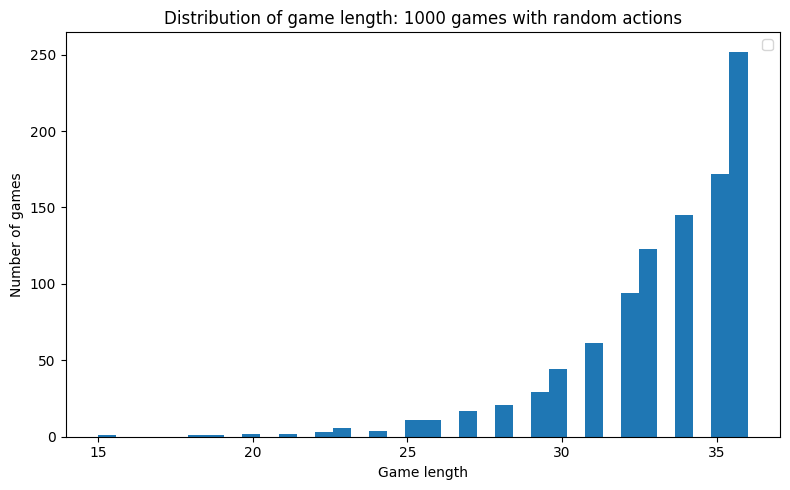

In [9]:
game_lengths = np.array(game_lengths)

plt.figure(figsize=(8,5))
plt.hist(game_lengths, bins=36)
plt.xlabel('Game length')
plt.ylabel('Number of games')
plt.title(f'Distribution of game length: {N_eps} games with random actions')
plt.legend()
plt.tight_layout()
plt.show()

# Q agent

In [10]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

q_config = {'gamma':0.9
            ,'epsilon':1.0
            ,'alpha':0.1
            ,'A':A
           }
N_train = 6000
eps_start, eps_end = 1.0, 0.05

def train_q_agent(state_idx, n_episodes=N_train, name_of_agent="q_agent",
                  config=q_config, eps_start=eps_start, eps_end=eps_end):
    env = Battleship({**env_config})
    q_agent = QAgent(dict(config), state_idx=state_idx)
    rewards, turns = [], []
    for episode in range(n_episodes):
        if episode % 500 == 0:
            print(f"name: {name_of_agent}, episode {episode}")
        
        q_agent.epsilon = eps_start + (eps_end - eps_start) * episode / (n_episodes - 1)
        env.reset()
        s = env.get_state()
        done, total_r, t = False, 0, 0
        while not done:
            a = q_agent.pi(s)
            out = env.step(q_agent.action_to_dict(a))
            q_agent.update_Q(s, a, out['reward'], out['state'])
            s = out['state']
            done = out['done']
            total_r += out['reward']
            t += 1
        rewards.append(total_r)
        turns.append(t)
    return q_agent, np.array(rewards), np.array(turns)

In [11]:
board_only_agent, board_only_rewards, board_only_turns = train_q_agent([0], name_of_agent = "Board Only")
all_states_agent, all_states_rewards, all_states_turns = train_q_agent([0, 1, 2], name_of_agent = "All States")
without_board_state_agent, without_board_state_rewards, without_board_state_turns = train_q_agent([1, 2], name_of_agent = "Without board state")

print(f"Board Only: avg reward = {board_only_rewards[-500:].mean()}, avg turns = {board_only_turns[-500:].mean()}")
print(f"All state information : avg reward = {all_states_rewards[-500:].mean()}, avg turns = {all_states_turns[-500:].mean()}")
print(f"Without board information : avg reward = {without_board_state_rewards[-500:].mean()}, avg turns = {without_board_state_turns[-500:].mean()}")

name: Board Only, episode 0
name: Board Only, episode 500
name: Board Only, episode 1000
name: Board Only, episode 1500
name: Board Only, episode 2000
name: Board Only, episode 2500
name: Board Only, episode 3000
name: Board Only, episode 3500
name: Board Only, episode 4000
name: Board Only, episode 4500
name: Board Only, episode 5000
name: Board Only, episode 5500
name: All States, episode 0
name: All States, episode 500
name: All States, episode 1000
name: All States, episode 1500
name: All States, episode 2000
name: All States, episode 2500
name: All States, episode 3000
name: All States, episode 3500
name: All States, episode 4000
name: All States, episode 4500
name: All States, episode 5000
name: All States, episode 5500
name: Without board state, episode 0
name: Without board state, episode 500
name: Without board state, episode 1000
name: Without board state, episode 1500
name: Without board state, episode 2000
name: Without board state, episode 2500
name: Without board state, e

### Hyperparameter sweeps -- epsilon, alpha, gamma
Each sweep trains the full-state agent `[0, 1]` once per value, in parallel.

In [12]:
# had claude generate this cell to test the hyper paparemeters
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Run one sweep -- one process per value, then print final performance
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def run_sweep(runs):
    '''runs -- dict, name -> kwargs for train_q_agent. Returns name -> (rewards, turns)'''
    with ProcessPoolExecutor(max_workers=len(runs), mp_context=mp.get_context('fork')) as pool:
        futures = {name: pool.submit(train_q_agent, [1, 2], name_of_agent=name, **kwargs)
                   for name, kwargs in runs.items()}
        results = {name: f.result()[1:] for name, f in futures.items()}
    for name, (rewards, turns) in results.items():
        print(f"{name}: avg reward = {rewards[-500:].mean()}, avg turns = {turns[-500:].mean()}")
    return results

In [13]:
#epsilon -- fixed exploration rate (eps_start = eps_end) vs. the default 1.0 -> 0.05 decay
epsilon_results = run_sweep({
    'epsilon decay 1.0->0.05': {},
    'epsilon = 0.05': {'eps_start': 0.05, 'eps_end': 0.05},
    'epsilon = 0.1':  {'eps_start': 0.1,  'eps_end': 0.1},
    'epsilon = 0.3':  {'eps_start': 0.3,  'eps_end': 0.3},
    'epsilon = 0.6':  {'eps_start': 0.6,  'eps_end': 0.6},
    'epsilon = 1.0':  {'eps_start': 1.0,  'eps_end': 1.0},
})

name: epsilon decay 1.0->0.05, episode 0name: epsilon = 0.3, episode 0
name: epsilon = 0.6, episode 0name: epsilon = 0.1, episode 0name: epsilon = 0.05, episode 0name: epsilon = 1.0, episode 0




name: epsilon decay 1.0->0.05, episode 500
name: epsilon = 0.05, episode 500
name: epsilon = 0.6, episode 500
name: epsilon = 0.3, episode 500
name: epsilon = 0.05, episode 1000
name: epsilon decay 1.0->0.05, episode 1000
name: epsilon = 0.1, episode 500
name: epsilon = 1.0, episode 500
name: epsilon = 1.0, episode 1000
name: epsilon = 0.1, episode 1000
name: epsilon = 0.05, episode 1500
name: epsilon = 0.3, episode 1000
name: epsilon = 0.6, episode 1000
name: epsilon decay 1.0->0.05, episode 1500
name: epsilon = 0.1, episode 1500
name: epsilon = 1.0, episode 1500
name: epsilon decay 1.0->0.05, episode 2000
name: epsilon = 0.05, episode 2000
name: epsilon = 0.3, episode 1500
name: epsilon = 0.6, episode 1500
name: epsilon = 0.1, episode 2000
name: epsilon = 1.0, episode 2000
name: epsilon dec

In [14]:
#alpha -- learning rate
alpha_results = run_sweep({f'alpha = {a}': {'config': {**q_config, 'alpha': a}}
                           for a in [0.01, 0.1, 0.5, 1]})

name: alpha = 0.5, episode 0name: alpha = 0.1, episode 0name: alpha = 0.01, episode 0


name: alpha = 1, episode 0
name: alpha = 0.1, episode 500
name: alpha = 0.01, episode 500
name: alpha = 1, episode 500
name: alpha = 0.5, episode 500
name: alpha = 0.01, episode 1000
name: alpha = 0.1, episode 1000
name: alpha = 1, episode 1000
name: alpha = 0.5, episode 1000
name: alpha = 0.01, episode 1500
name: alpha = 0.1, episode 1500
name: alpha = 0.5, episode 1500
name: alpha = 1, episode 1500
name: alpha = 0.01, episode 2000
name: alpha = 0.1, episode 2000
name: alpha = 1, episode 2000
name: alpha = 0.5, episode 2000
name: alpha = 0.01, episode 2500
name: alpha = 0.1, episode 2500
name: alpha = 0.5, episode 2500
name: alpha = 1, episode 2500
name: alpha = 0.01, episode 3000
name: alpha = 0.1, episode 3000
name: alpha = 0.5, episode 3000
name: alpha = 0.01, episode 3500
name: alpha = 1, episode 3000
name: alpha = 0.1, episode 3500
name: alpha = 0.5, episode 3500
name: alpha = 0.01, episode 40

In [15]:
#gamma -- discount factor
gamma_results = run_sweep({f'gamma = {g}': {'config': {**q_config, 'gamma': g}}
                           for g in [0.01, 0.1, 0.5, 1]})

name: gamma = 0.01, episode 0name: gamma = 0.5, episode 0name: gamma = 0.1, episode 0
name: gamma = 1, episode 0


name: gamma = 0.1, episode 500
name: gamma = 0.01, episode 500
name: gamma = 0.5, episode 500
name: gamma = 1, episode 500
name: gamma = 0.01, episode 1000
name: gamma = 0.5, episode 1000
name: gamma = 1, episode 1000
name: gamma = 0.1, episode 1000
name: gamma = 0.5, episode 1500
name: gamma = 0.01, episode 1500
name: gamma = 0.1, episode 1500
name: gamma = 1, episode 1500
name: gamma = 0.5, episode 2000
name: gamma = 0.01, episode 2000
name: gamma = 1, episode 2000
name: gamma = 0.1, episode 2000
name: gamma = 0.01, episode 2500
name: gamma = 1, episode 2500
name: gamma = 0.5, episode 2500
name: gamma = 0.1, episode 2500
name: gamma = 0.01, episode 3000
name: gamma = 0.5, episode 3000
name: gamma = 1, episode 3000
name: gamma = 0.1, episode 3000
name: gamma = 0.5, episode 3500
name: gamma = 0.01, episode 3500
name: gamma = 1, episode 3500
name: gamma = 0.1, episode 3500


# DQN Agent

In [44]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Train the DQN agent -- [0], uses the current board as the state
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
dqn_config = {'gamma':0.9
              ,'epsilon':1.0
              ,'alpha':0.001
              ,'A':A
              ,'n':6
              ,'M':50000
              ,'B':32
              ,'C':500
              ,'n_steps_for_Q_update':4
              ,'ships':env_config['ships']
             }
N_dqn = 6000

def train_dqn_agent(state_idx, n_episodes=N_dqn, name_of_agent="dqn_agent"):
    '''A function to train one DQN Agent
        Takes:
            state_idx -- list of state indices the agent uses, passed to Agent
            n_episodes -- int, number of training episodes
        Returns:
            the trained agent, and arrays of total reward and turns per episode
    '''
    #one thread per process keeps forked PyTorch workers from deadlocking
    torch.set_num_threads(1)
    env = Battleship(env_config)
    dqn_agent = Agent(dict(dqn_config), state_idx=state_idx)
    rewards = []
    turns = []
    env_steps = 0
    for episode in range(n_episodes):
        if episode % 500 == 0:
            print(f"name: {name_of_agent} episode: {episode}")
        dqn_agent.config['epsilon'] = eps_start + (eps_end - eps_start) * episode / (n_episodes - 1)
        env.reset()
        s = dqn_agent.make_state(env.get_state())
        valid = dqn_agent.valid_actions(env.get_state())
        done, total_r, t = False, 0, 0
        while not done:
            a = dqn_agent.pi(s, valid)
            out = env.step(dqn_agent.action_to_dict(a))
            s_prime = dqn_agent.make_state(out['state'])
            valid = dqn_agent.valid_actions(out['state'])
            done = out['done']
            dqn_agent.add_to_replay_buffer(s, a, out['reward'], s_prime, done, valid)
            env_steps += 1
            if env_steps % dqn_config['n_steps_for_Q_update'] == 0:
                dqn_agent.update_Q_value()
            s = s_prime
            total_r += out['reward']
            t += 1
        rewards.append(total_r)
        turns.append(t)
    return dqn_agent, np.array(rewards), np.array(turns)

## 3.3.3 Checkpoints

In [45]:
checkpoints = [500, 5000, 10000, 20000]
N_total = checkpoints[-1]

with ProcessPoolExecutor(max_workers=3, mp_context=mp.get_context('fork')) as pool:
    futures = {'q_board': pool.submit(train_q_agent, [0], N_total),
               'q_my_representation':  pool.submit(train_q_agent, [1, 2], N_total),
               'dqn':     pool.submit(train_dqn_agent, [0], N_total),
               'dqn_my_representation':     pool.submit(train_dqn_agent, [1, 2], N_total)}
    training_log = {}
    for name, f in futures.items():
        agent, rewards, turns = f.result()
        training_log[name] = {'agent': agent, 'rewards': rewards, 'turns': turns}

for name, log in training_log.items():
    print(name)
    start = 0
    for ckpt in checkpoints:
        avg_reward = log['rewards'][start:ckpt].mean()
        avg_turns = log['turns'][start:ckpt].mean()
        print(f"episodes {start} to {ckpt}: avg reward = {avg_reward}, avg turns = {avg_turns}")
        start = ckpt


name: q_agent, episode 0name: q_agent, episode 0

name: dqn_agent episode: 0
name: q_agent, episode 500
name: q_agent, episode 500
name: q_agent, episode 1000
name: q_agent, episode 1000
name: q_agent, episode 1500
name: q_agent, episode 1500
name: q_agent, episode 2000
name: q_agent, episode 2000
name: q_agent, episode 2500
name: q_agent, episode 2500
name: q_agent, episode 3000
name: q_agent, episode 3000
name: q_agent, episode 3500
name: q_agent, episode 3500
name: q_agent, episode 4000
name: q_agent, episode 4000
name: q_agent, episode 4500
name: q_agent, episode 4500
name: q_agent, episode 5000
name: dqn_agent episode: 500
name: q_agent, episode 5500
name: q_agent, episode 5000
name: q_agent, episode 6000
name: q_agent, episode 5500
name: q_agent, episode 6500
name: q_agent, episode 6000
name: q_agent, episode 7000
name: q_agent, episode 6500
name: q_agent, episode 7500
name: q_agent, episode 7000
name: q_agent, episode 8000
name: q_agent, episode 7500
name: q_agent, episode 8500


In [46]:
with ProcessPoolExecutor(max_workers=3, mp_context=mp.get_context('fork')) as pool:
    futures = {'dqn_all':     pool.submit(train_dqn_agent, [0, 1, 2], N_total)}
    training_log = {}
    for name, f in futures.items():
        agent, rewards, turns = f.result()
        training_log[name] = {'agent': agent, 'rewards': rewards, 'turns': turns}

for name, log in training_log.items():
    print(name)
    start = 0
    for ckpt in checkpoints:
        avg_reward = log['rewards'][start:ckpt].mean()
        avg_turns = log['turns'][start:ckpt].mean()
        print(f"  episodes {start} to {ckpt}: avg reward = {avg_reward}, avg turns = {avg_turns}")
        start = ckpt


name: dqn_agent episode: 0
name: dqn_agent episode: 500
name: dqn_agent episode: 1000
name: dqn_agent episode: 1500
name: dqn_agent episode: 2000
name: dqn_agent episode: 2500
name: dqn_agent episode: 3000
name: dqn_agent episode: 3500
name: dqn_agent episode: 4000
name: dqn_agent episode: 4500
name: dqn_agent episode: 5000
name: dqn_agent episode: 5500
name: dqn_agent episode: 6000
name: dqn_agent episode: 6500
name: dqn_agent episode: 7000
name: dqn_agent episode: 7500
name: dqn_agent episode: 8000
name: dqn_agent episode: 8500
name: dqn_agent episode: 9000
name: dqn_agent episode: 9500
name: dqn_agent episode: 10000
name: dqn_agent episode: 10500
name: dqn_agent episode: 11000
name: dqn_agent episode: 11500
name: dqn_agent episode: 12000
name: dqn_agent episode: 12500
name: dqn_agent episode: 13000
name: dqn_agent episode: 13500
name: dqn_agent episode: 14000
name: dqn_agent episode: 14500
name: dqn_agent episode: 15000
name: dqn_agent episode: 15500
name: dqn_agent episode: 16000
n

## 4. Ablations

### 4.1 Engineered representation

In [20]:
# Have full for a baseline, then do our representation removing other parts
ablation_reps = {'full': [0, 1, 2], 'my_representation': [1, 2], 'my_representation_with_no_ships_left': [2], 'my_representation_with_no_unsunk_hits': [1]}
ablation = {}
for name, rep in ablation_reps.items():
    agents, rewards, turns = train_q_agent(rep, name_of_agent=name)
    ablation[name] = {'rewards': rewards, 'turns': turns}


name: full, episode 0
name: full, episode 500
name: full, episode 1000
name: full, episode 1500
name: full, episode 2000
name: full, episode 2500
name: full, episode 3000
name: full, episode 3500
name: full, episode 4000
name: full, episode 4500
name: full, episode 5000
name: full, episode 5500
name: my_representation, episode 0
name: my_representation, episode 500
name: my_representation, episode 1000
name: my_representation, episode 1500
name: my_representation, episode 2000
name: my_representation, episode 2500
name: my_representation, episode 3000
name: my_representation, episode 3500
name: my_representation, episode 4000
name: my_representation, episode 4500
name: my_representation, episode 5000
name: my_representation, episode 5500
name: my_representation_with_no_ships_left, episode 0
name: my_representation_with_no_ships_left, episode 500
name: my_representation_with_no_ships_left, episode 1000
name: my_representation_with_no_ships_left, episode 1500
name: my_representation_with

full turns per block: [33.3 33.3 33.3 33.4 33.2 33.1] final: avg reward = 54.824, avg turns = 33.028
my_representation turns per block: [32.8 31.3 30.  28.1 25.6 23.5] final: avg reward = 60.266, avg turns = 22.544
my_representation_with_no_ships_left turns per block: [32.4 30.5 27.7 25.9 23.9 21.7] final: avg reward = 61.766, avg turns = 21.528
my_representation_with_no_unsunk_hits turns per block: [33.2 32.9 33.  32.8 32.4 32.5] final: avg reward = 55.994, avg turns = 32.562


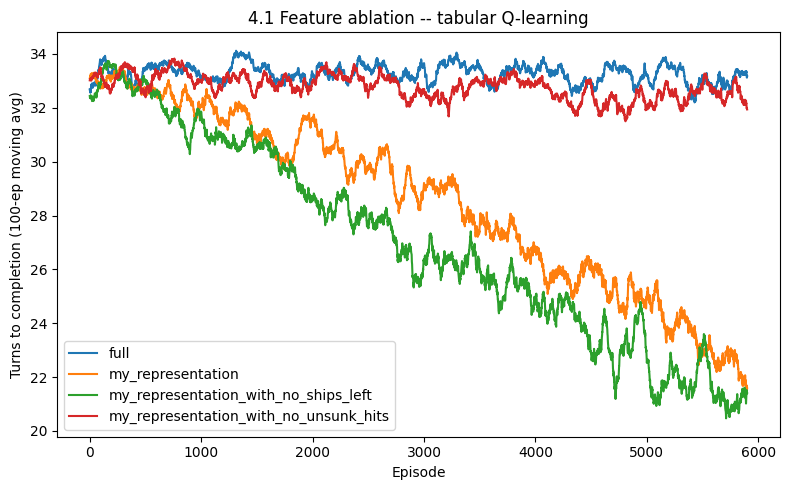

In [53]:
block, final_window = 1000, 500
for name, res in ablation.items():
    blocks = res['turns'].reshape(-1, block).mean(axis=1)
    print(f"{name} turns per block: {np.round(blocks, 1)} final: avg reward = {res['rewards'][-final_window:].mean()}, avg turns = {res['turns'][-final_window:].mean()}")

plt.figure(figsize=(8,5))
for name, res in ablation.items():
    # Needed otherwise graph looks bad with raw data
    smooth = np.convolve(res['turns'], np.ones(100)/100, mode='valid')
    plt.plot(smooth, label=name)
plt.xlabel('Episode')
plt.ylabel('Turns to completion (100-ep moving avg)')
plt.title('4.1 Feature ablation -- tabular Q-learning')
plt.legend()
plt.tight_layout()
plt.show()


## 5. Learned policies
Tabular Q-learning with state `[1, 2]` vs. DQN with state `[0, 1, 2]`.

In [55]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Train the two agents we compare, in parallel
#  q_policy_agent   -- tabular Q-learning, state [1, 2] (ships still afloat + unsunk hits)
#  dqn_policy_agent -- DQN, state [0, 1, 2] (Everything)
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
with ProcessPoolExecutor(max_workers=2, mp_context=mp.get_context('fork')) as pool:
    q_future = pool.submit(train_q_agent, [1, 2], name_of_agent='Q-learning [1, 2]')
    dqn_future = pool.submit(train_dqn_agent, [0, 1, 2])
    q_policy_agent, _, _ = q_future.result()
    dqn_policy_agent, _, _ = dqn_future.result()


name: Q-learning [1, 2], episode 0
name: dqn_agent episode: 0
name: Q-learning [1, 2], episode 500
name: Q-learning [1, 2], episode 1000
name: Q-learning [1, 2], episode 1500
name: Q-learning [1, 2], episode 2000
name: Q-learning [1, 2], episode 2500
name: Q-learning [1, 2], episode 3000
name: Q-learning [1, 2], episode 3500
name: Q-learning [1, 2], episode 4000
name: Q-learning [1, 2], episode 4500
name: dqn_agent episode: 500
name: Q-learning [1, 2], episode 5000
name: Q-learning [1, 2], episode 5500
name: dqn_agent episode: 1000
name: dqn_agent episode: 1500
name: dqn_agent episode: 2000
name: dqn_agent episode: 2500
name: dqn_agent episode: 3000
name: dqn_agent episode: 3500
name: dqn_agent episode: 4000
name: dqn_agent episode: 4500
name: dqn_agent episode: 5000
name: dqn_agent episode: 5500


In [56]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Helpers -- Q-values, greedy play, and fixed board situations
#Both agents play greedily (epsilon = 0) and only pick cells not yet fired at
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
from matplotlib.colors import ListedColormap

def q_values(agent, s):
    if isinstance(agent, QAgent):
        return agent.Q.get(agent.make_state(s), np.zeros(len(agent.A_s))).copy()
    with torch.no_grad():
        return agent.forward_pass(agent.make_state(s))[0].numpy().copy()

def greedy_action(agent, s):
    q = q_values(agent, s)
    q[np.array(s[0]).flatten() != 0] = -np.inf
    return np.random.choice(np.flatnonzero(q == q.max()))

def play_game(agent, seed):
    np.random.seed(seed)
    env = Battleship(env_config)
    env.reset()
    s = env.get_state()
    states, shots, done = [], [], False
    while not done:
        a = greedy_action(agent, s)
        states.append(s)
        shots.append(a)
        out = env.step(agent.action_to_dict(a))
        s, done = out['state'], out['done']
    return env, states, shots

fleet = [[(0, 0), (0, 1)], [(2, 4), (3, 4), (4, 4)], [(5, 1), (5, 2), (5, 3), (5, 4)]]

def scenario(shots):
    env = Battleship(env_config)
    env.reset()
    env.true_state[:] = 0
    env.ship_cells = []
    for cells in fleet:
        rows, cols = map(np.array, zip(*cells))
        env.ship_cells.append((rows, cols))
        env.true_state[rows, cols] = 1
    for r, c in shots:
        env.step({'row': r, 'col': c})
    return env.get_state()

agents = {'Q-learning [1, 2]': q_policy_agent, 'DQN [1, 2, 3]': dqn_policy_agent}


### 5.1 Target-selection heatmaps

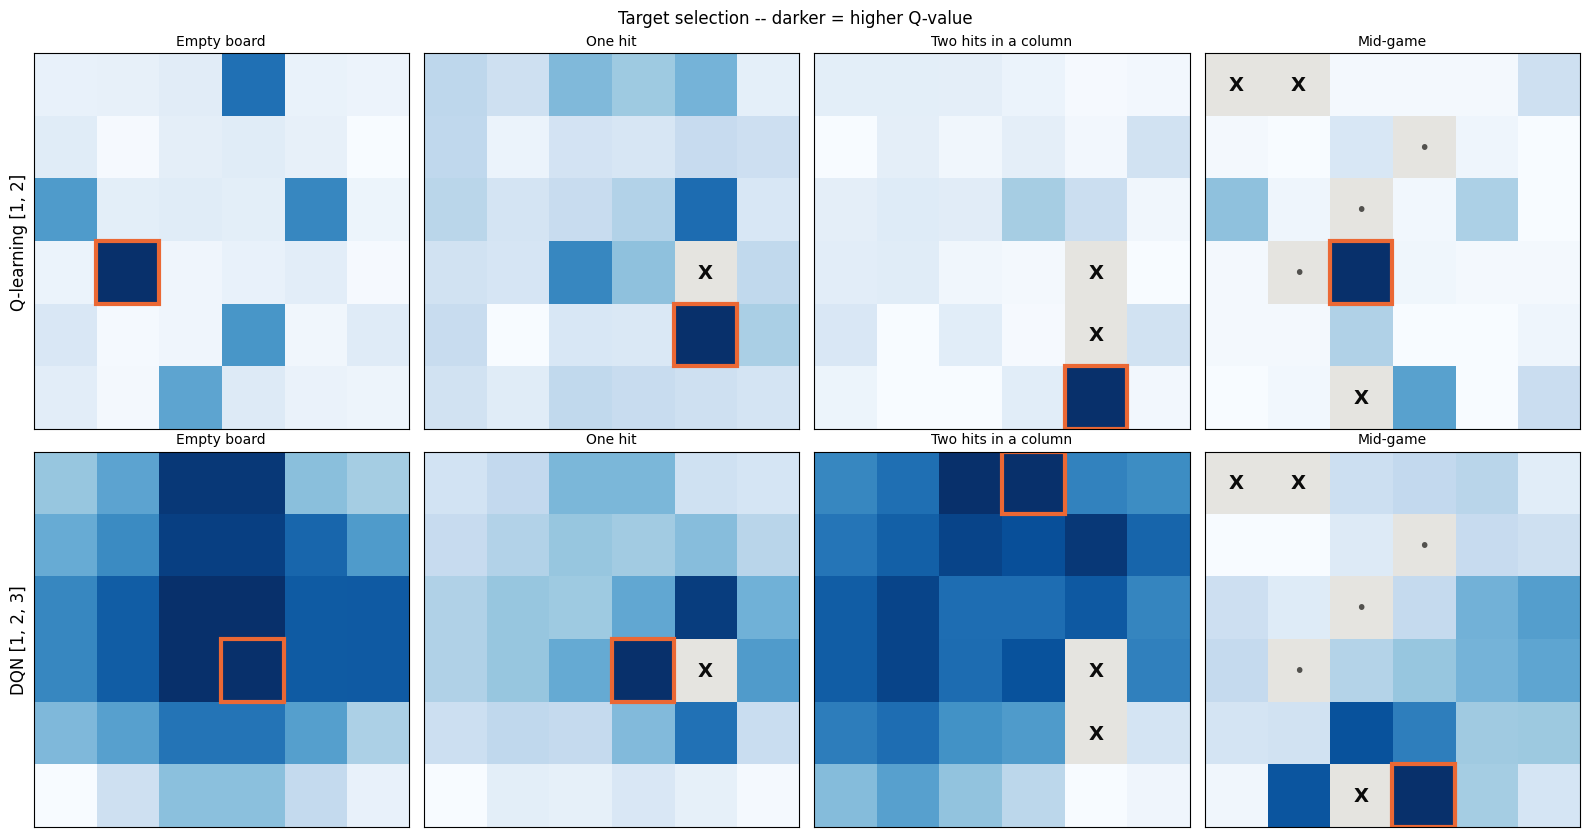

In [57]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Target-selection heatmaps -- Q(s, a) for every cell in four board situations
#  X = hit, dot = miss, gray = already fired at, orange box = the cell the agent picks
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
scenarios = {'Empty board': [],
             'One hit': [(3, 4)],
             'Two hits in a column': [(3, 4), (4, 4)],
             'Mid-game': [(0, 0), (0, 1), (2, 2), (1, 3), (3, 1), (5, 2)]}

cmap = plt.get_cmap('Blues').copy()
cmap.set_bad('#e5e4e0')
fig, axes = plt.subplots(len(agents), len(scenarios), figsize=(4 * len(scenarios), 4.3 * len(agents)))
for row, (agent_name, agent_) in enumerate(agents.items()):
    for col, (scen_name, shots) in enumerate(scenarios.items()):
        ax = axes[row, col]
        s = scenario(shots)
        board = np.array(s[0])
        q = q_values(agent_, s).reshape(6, 6)
        q[board != 0] = np.nan
        ax.imshow(q, cmap=cmap)
        for (r, c), v in np.ndenumerate(board):
            if v == 1:
                ax.text(c, r, 'X', ha='center', va='center', fontsize=14, fontweight='bold', color='#0b0b0b')
            elif v == -1:
                ax.text(c, r, '•', ha='center', va='center', fontsize=14, color='#52514e')
        r, c = divmod(greedy_action(agent_, s), 6)
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec='#eb6834', lw=3))
        unseen = isinstance(agent_, QAgent) and agent_.make_state(s) not in agent_.Q
        ax.set_title(f"{scen_name}{' (unseen state)' if unseen else ''}", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(agent_name, fontsize=12)
fig.suptitle('Target selection -- darker = higher Q-value')
fig.tight_layout()
plt.show()


### 5.2 Representative games

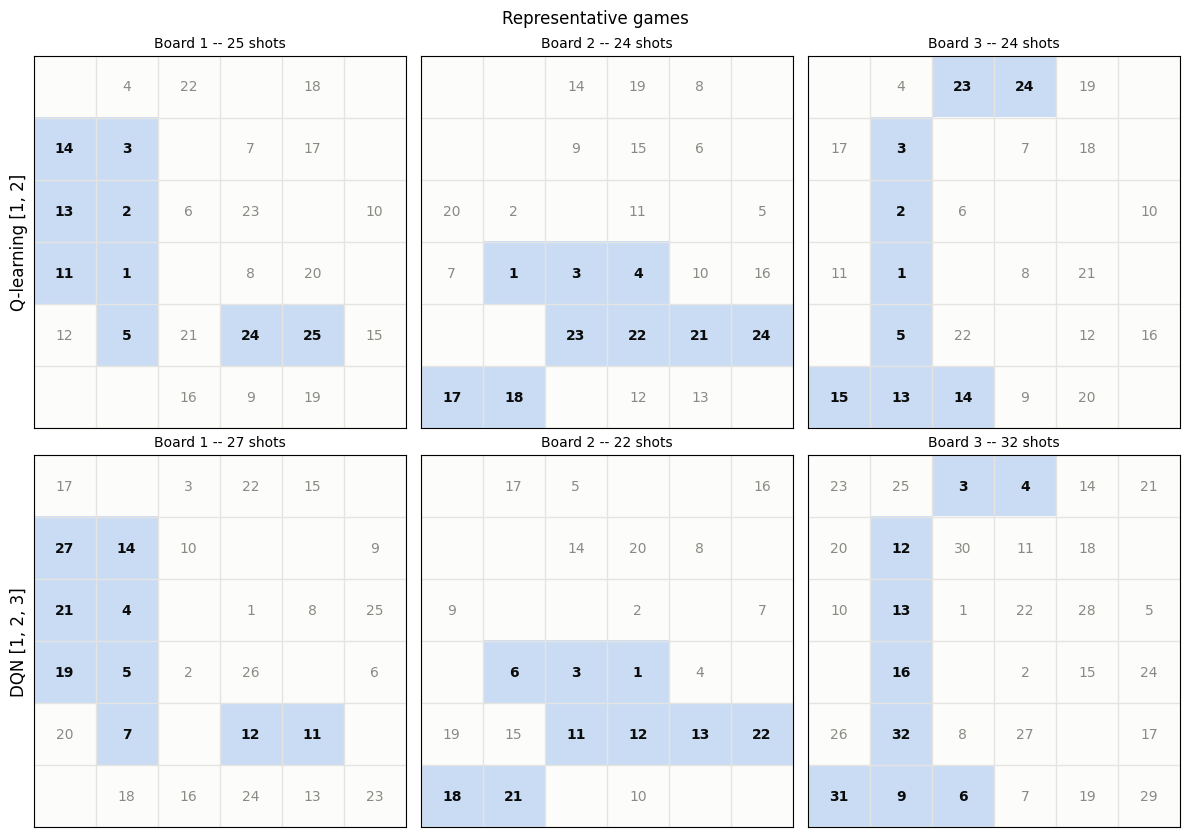

In [58]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Representative games -- same three boards for both agents
#  blue cells = ships, numbers = shot order, bold = hit
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
game_seeds = [1, 2, 3]
fig, axes = plt.subplots(len(agents), len(game_seeds), figsize=(4 * len(game_seeds), 4.3 * len(agents)))
for row, (agent_name, agent_) in enumerate(agents.items()):
    for col, seed in enumerate(game_seeds):
        ax = axes[row, col]
        env, _, shots = play_game(agent_, seed)
        ax.imshow(env.true_state, cmap=ListedColormap(['#fcfcfb', '#c9dcf3']), vmin=0, vmax=1)
        for i, a in enumerate(shots, 1):
            r, c = divmod(a, 6)
            hit = env.true_state[r, c] == 1
            ax.text(c, r, str(i), ha='center', va='center', fontsize=10,
                    fontweight='bold' if hit else 'normal', color='#0b0b0b' if hit else '#8a8984')
        ax.set_xticks(np.arange(-0.5, 6), minor=True)
        ax.set_yticks(np.arange(-0.5, 6), minor=True)
        ax.grid(which='minor', color='#e5e4e0', lw=1)
        ax.tick_params(which='both', length=0, labelbottom=False, labelleft=False)
        ax.set_title(f'Board {seed} -- {len(shots)} shots', fontsize=10)
    axes[row, 0].set_ylabel(agent_name, fontsize=12)
fig.suptitle('Representative games')
fig.tight_layout()
plt.show()


In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Action distributions over 500 greedy games per agent
#  hunting -- where the agent fires when no ship is partly hit
#  follow-up rate -- when a ship is partly hit, how often the next shot is next to a hit
#  repeat pick -- how often the agent's top cell (no masking) was already fired at
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
n_games = 500
stats = {}
for agent_name, agent_ in agents.items():
    hunt_counts = np.zeros(36)
    lengths, follow, follow_total, repeat, total = [], 0, 0, 0, 0
    for seed in range(1000, 1000 + n_games):
        _, states, shots = play_game(agent_, seed)
        lengths.append(len(shots))
        for s, a in zip(states, shots):
            r, c = divmod(a, 6)
            if s[2] == ():
                hunt_counts[a] += 1
            else:
                follow_total += 1
                follow += any(abs(r - hr) + abs(c - hc) == 1 for hr, hc in s[2])
            repeat += np.array(s[0]).flatten()[np.argmax(q_values(agent_, s))] != 0
            total += 1
    stats[agent_name] = {'hunt': hunt_counts / hunt_counts.sum(), 'lengths': np.array(lengths),
                         'follow_up': follow / follow_total, 'repeat': repeat / total}

for agent_name, st in stats.items():
    print(f"{agent_name}: avg turns = {st['lengths'].mean():.2f}, follow-up rate = {st['follow_up']:.0%}, "
          f"top cell already fired at = {st['repeat']:.0%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.6]})
for ax, (agent_name, st) in zip(axes[:2], stats.items()):
    im = ax.imshow(st['hunt'].reshape(6, 6), cmap='Blues', vmin=0)
    for (r, c), v in np.ndenumerate(st['hunt'].reshape(6, 6)):
        ax.text(c, r, f'{v:.0%}', ha='center', va='center', fontsize=8,
                color='white' if v > st['hunt'].max() * 0.6 else '#0b0b0b')
    ax.set_title(f'{agent_name} -- hunting shots', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
colors = ['#2a78d6', '#eb6834']
bins = np.arange(9, 38)
for (agent_name, st), color in zip(stats.items(), colors):
    axes[2].hist(st['lengths'], bins=bins, color=color, histtype='step', lw=2, label=agent_name)
axes[2].axvline(9 * 37 / 10, color='#52514e', ls='--', lw=1, label='random untried cell (33.3)')
axes[2].set_xlabel('Turns to finish')
axes[2].set_ylabel('Games')
axes[2].legend(frameon=False)
axes[2].spines[['top', 'right']].set_visible(False)
fig.suptitle(f'Action distributions -- {n_games} greedy games per agent')
fig.tight_layout()
plt.show()
